# 09. Transfer Learning and Pretrained Models

**Deep Learning with TensorFlow | Beginner to Intermediate**

This notebook introduces transfer learning for image classification. We will reuse an ImageNet-pretrained convolutional backbone, replace its original classifier, train a new classification head, and then selectively fine-tune upper layers.

> **Central workflow:** load a pretrained model → remove its original classifier → freeze the backbone → train a new head → optionally unfreeze selected layers → fine-tune with a very small learning rate.

**Practical dataset:** a balanced four-class subset of CIFAR-10 (`airplane`, `automobile`, `ship`, and `truck`). The notebook resizes the original 32 × 32 images to 96 × 96 for the pretrained backbone. CIFAR-10 is a general-purpose educational dataset, not a medical imaging dataset.

**Runtime note:** the first run downloads CIFAR-10 and ImageNet weights for MobileNetV2. A GPU is helpful but not required. To reduce runtime, lower `MAX_TRAIN_PER_CLASS`, `IMG_SIZE`, or the number of epochs.

## Learning objectives

By the end of this notebook, you should be able to:

1. Explain transfer learning, feature extraction, and fine-tuning.
2. Load a pretrained Keras Application with `include_top=False`.
3. Explain why the original classifier is replaced and why Global Average Pooling is commonly used.
4. Apply the preprocessing expected by a selected pretrained architecture.
5. Freeze a backbone and train a task-specific classification head.
6. Fine-tune only selected upper layers using a low learning rate.
7. Handle Batch Normalization safely during fine-tuning.
8. Compare MobileNetV2, ResNet50, and EfficientNetB0 at a conceptual and architectural level.
9. Evaluate the final model without using the test set for model selection.
10. Recognize domain-shift and data-leakage risks when transferring models to biomedical images.

## 1. What is transfer learning?

Transfer learning reuses knowledge learned on a source task to improve learning on a related target task. In image classification, the source model is often trained on a large dataset such as ImageNet. Its early and intermediate layers learn reusable visual patterns such as edges, textures, corners, and object parts.

The target task usually has a different set of classes. We therefore remove the original ImageNet classifier and attach a new head whose output dimension matches the target classes.

### Key terms

- **Pretrained model:** a model whose weights were learned on a source dataset.
- **Backbone:** the feature-extraction part of the network.
- **Feature extraction:** keep the pretrained backbone frozen and train only the newly added head.
- **Fine-tuning:** unfreeze some or all pretrained layers and continue training them on the target dataset.
- **Domain shift:** a difference between the source and target data distributions.

The basic idea is to start from parameters that already encode useful visual features instead of learning every parameter from random initialization.

## 2. Feature extraction versus fine-tuning

### Stage A — Feature extraction

1. Load the pretrained backbone.
2. Set `backbone.trainable = False`.
3. Add a new classifier.
4. Train only the new classifier.

This is a strong first choice when the target dataset is small or similar enough to the source domain.

### Stage B — Fine-tuning

1. Start from the feature-extraction model after its new head has converged.
2. Unfreeze a selected group of upper backbone layers.
3. Keep Batch Normalization layers frozen/in inference mode as a safe default.
4. Recompile the model.
5. Continue training with a much smaller learning rate.

Fine-tuning can improve task-specific features, but it can also overfit or damage useful pretrained representations when the learning rate is too high.

<figure>

| Strategy | Backbone weights | New head | Typical learning rate |
|---|---|---|---|
| Feature extraction | Frozen | Trainable | Around `1e-3` (task-dependent) |
| Fine-tuning | Selected layers trainable | Trainable | Much smaller, e.g. `1e-5` |

</figure>

### Mathematical view: adapting a pretrained representation

Let a pretrained backbone be a function $f_{\theta}(x)$ with parameters $\theta$, and let a newly initialized classifier be $g_{\phi}(\cdot)$ with parameters $\phi$.

The prediction is:

$$
\hat{y} = g_{\phi}(f_{\theta}(x))
$$

During feature extraction, the backbone is fixed and only the new head is optimized:

$$
\theta \text{ is fixed}, \qquad \phi \leftarrow \phi - \eta\nabla_{\phi}\mathcal{L}
$$

During fine-tuning, selected backbone parameters are also updated:

$$
(\theta_{\mathrm{selected}},\phi) \leftarrow (\theta_{\mathrm{selected}},\phi) - \eta\nabla_{(\theta_{\mathrm{selected}},\phi)}\mathcal{L}
$$

The smaller fine-tuning learning rate helps preserve useful source-task representations while allowing gradual adaptation.

## 3. Why `include_top=False`?

Keras Applications usually include a classification head designed for the 1,000 ImageNet classes. For a new task, that head is not appropriate.

Setting `include_top=False` removes the original classifier and returns the final convolutional feature maps instead. We then add our own pooling and classification layers.

If the backbone output has shape $(H,W,C)$, Global Average Pooling computes one average per channel:

$$
z_c = \frac{1}{HW}\sum_{i=1}^{H}\sum_{j=1}^{W} A_{i,j,c}
$$

The resulting vector has $C$ features. This is much smaller than flattening all $H\times W\times C$ activations and usually introduces fewer classifier parameters.

`pooling="avg"` can perform this operation inside a Keras Application. In this notebook we keep `pooling=None` initially so that the convolutional feature map shape is visible, then add `GlobalAveragePooling2D` explicitly.

## 4. Imports and reproducibility

We will use TensorFlow/Keras for the model, NumPy and Matplotlib for data inspection, and scikit-learn for stratified sampling and evaluation metrics.

In [1]:
import os
import gc
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.linear_model import LogisticRegression

SEED = 42
keras.utils.set_random_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__ if hasattr(keras, "__version__") else "bundled tf.keras")
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Keras: 3.15.1
Available GPUs: []


## 5. Load CIFAR-10 and select four classes

CIFAR-10 contains 10 image classes. We choose four vehicle-related classes that have reasonably close ImageNet concepts:

| Original label | Class |
|---:|---|
| 0 | airplane |
| 1 | automobile |
| 8 | ship |
| 9 | truck |

The original CIFAR-10 images are RGB arrays with shape `(32, 32, 3)`. We will resize them to `96 × 96` for MobileNetV2.

The Keras dataset utility downloads CIFAR-10 once and caches it locally.

In [2]:
(x_train_full, y_train_full), (x_test_full, y_test_full) = keras.datasets.cifar10.load_data()
y_train_full = y_train_full.reshape(-1)
y_test_full = y_test_full.reshape(-1)

SELECTED_ORIGINAL_IDS = [0, 1, 8, 9]
CLASS_NAMES = ["airplane", "automobile", "ship", "truck"]
ORIGINAL_TO_NEW = {original_id: new_id for new_id, original_id in enumerate(SELECTED_ORIGINAL_IDS)}
NUM_CLASSES = len(CLASS_NAMES)


def filter_and_remap(images, labels):
    mask = np.isin(labels, SELECTED_ORIGINAL_IDS)
    selected_images = images[mask]
    selected_labels = np.array(
        [ORIGINAL_TO_NEW[int(label)] for label in labels[mask]],
        dtype=np.int32,
    )
    return selected_images, selected_labels


x_train_all, y_train_all = filter_and_remap(x_train_full, y_train_full)
x_test_all, y_test_all = filter_and_remap(x_test_full, y_test_full)

print("Filtered training pool:", x_train_all.shape, y_train_all.shape)
print("Filtered test pool:", x_test_all.shape, y_test_all.shape)

Filtered training pool: (20000, 32, 32, 3) (20000,)
Filtered test pool: (4000, 32, 32, 3) (4000,)


## 6. Create stratified train, validation, and test subsets

We split only the original CIFAR-10 training partition into training and validation data. The official test partition remains untouched until final evaluation.

To keep the practical experiment manageable, we cap the number of examples per class. Change the values below to trade runtime for data volume.

> **Biomedical data warning:** for medical imaging, random image-level splitting is often unsafe when multiple images come from the same patient. Use patient-level (and, where appropriate, site-level) splitting so images from one patient cannot appear in both training and test sets.

In [3]:
MAX_TRAIN_PER_CLASS = 1000
MAX_VAL_PER_CLASS = 250
MAX_TEST_PER_CLASS = 300

x_train_pool, x_val_pool, y_train_pool, y_val_pool = train_test_split(
    x_train_all,
    y_train_all,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_all,
)


def balanced_subsample(images, labels, n_per_class, seed=SEED):
    rng = np.random.default_rng(seed)
    chosen_indices = []
    for class_id in np.unique(labels):
        class_indices = np.flatnonzero(labels == class_id)
        n_take = min(n_per_class, len(class_indices))
        chosen_indices.extend(rng.choice(class_indices, size=n_take, replace=False))
    chosen_indices = np.asarray(chosen_indices, dtype=np.int64)
    rng.shuffle(chosen_indices)
    return images[chosen_indices], labels[chosen_indices]


x_train, y_train = balanced_subsample(x_train_pool, y_train_pool, MAX_TRAIN_PER_CLASS, SEED)
x_val, y_val = balanced_subsample(x_val_pool, y_val_pool, MAX_VAL_PER_CLASS, SEED + 1)
x_test, y_test = balanced_subsample(x_test_all, y_test_all, MAX_TEST_PER_CLASS, SEED + 2)

print("Train:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)

Train: (4000, 32, 32, 3) (4000,)
Validation: (1000, 32, 32, 3) (1000,)
Test: (1200, 32, 32, 3) (1200,)


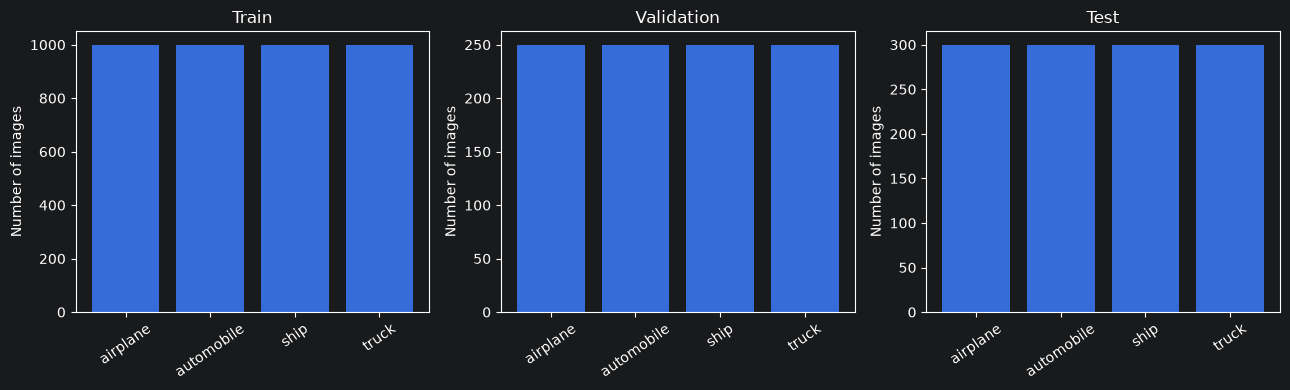

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, labels, title in zip(
    axes,
    [y_train, y_val, y_test],
    ["Train", "Validation", "Test"],
):
    counts = np.bincount(labels, minlength=NUM_CLASSES)
    ax.bar(CLASS_NAMES, counts)
    ax.set_title(title)
    ax.set_ylabel("Number of images")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

The class counts should be balanced by construction. Stratification preserves class proportions during the initial train/validation split; the balanced subsampling step then caps each class equally.

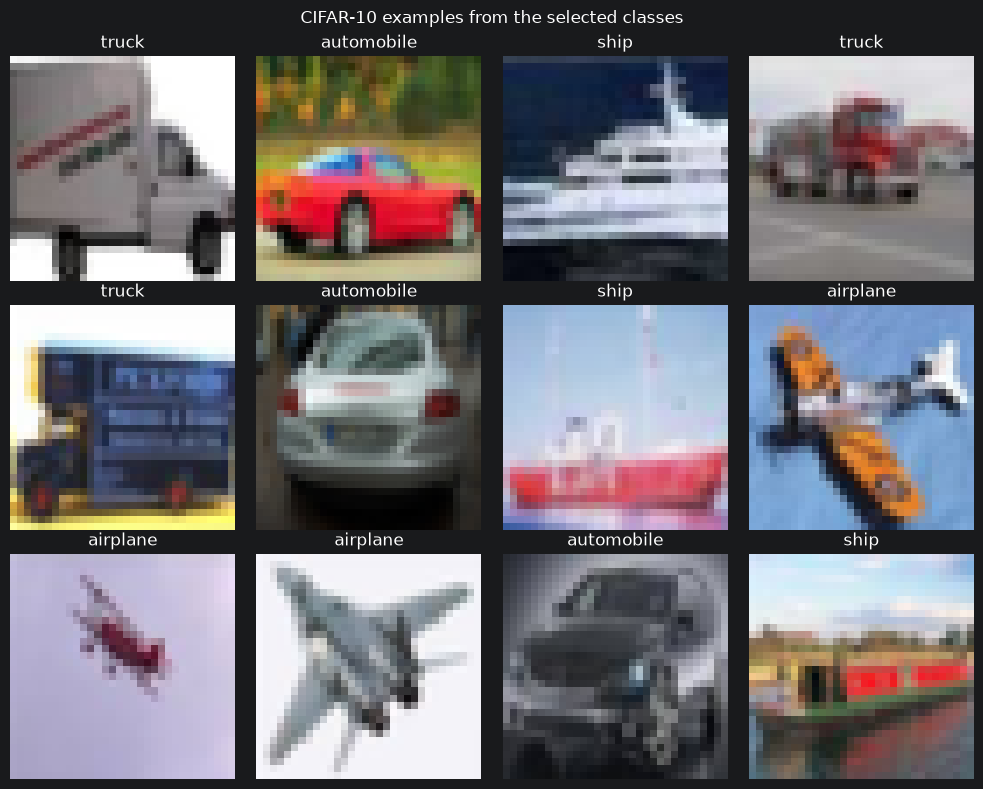

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for ax, image, label in zip(axes.flat, x_train[:12], y_train[:12]):
    ax.imshow(image)
    ax.set_title(CLASS_NAMES[int(label)])
    ax.axis("off")
plt.suptitle("CIFAR-10 examples from the selected classes")
plt.tight_layout()
plt.show()

## 7. Build an efficient `tf.data` pipeline

The raw images are stored as `uint8` arrays with values from 0 to 255. We resize each image and cast it to `float32`. We do **not** apply MobileNetV2 preprocessing in this dataset function; instead, we will put the corresponding rescaling operation inside the model so that the saved model accepts raw RGB pixel values.

We keep a non-shuffled training dataset as well. It is useful for feature caching because cached feature vectors must stay aligned with their labels.

In [6]:
IMG_SIZE = (96, 96)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


def resize_image(image, label):
    image = tf.cast(image, tf.float32)
    image = tf.image.resize(image, IMG_SIZE, antialias=True)
    label = tf.cast(label, tf.int32)
    return image, label


def make_dataset(images, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(images), 2000),
            seed=SEED,
            reshuffle_each_iteration=True,
        )
    dataset = dataset.map(resize_image, num_parallel_calls=AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return dataset


train_ds = make_dataset(x_train, y_train, training=True)
train_eval_ds = make_dataset(x_train, y_train, training=False)
val_ds = make_dataset(x_val, y_val, training=False)
test_ds = make_dataset(x_test, y_test, training=False)

for images, labels in train_ds.take(1):
    print("Image batch:", images.shape, images.dtype)
    print("Label batch:", labels.shape, labels.dtype)
    print("Pixel range:", float(tf.reduce_min(images)), float(tf.reduce_max(images)))

Image batch: (32, 96, 96, 3) <dtype: 'float32'>
Label batch: (32,) <dtype: 'int32'>
Pixel range: 0.0 255.0


## 8. Application-specific input preprocessing

Different pretrained architectures were trained with different image preprocessing conventions. Using the wrong convention can substantially reduce performance even when the model architecture and weights are correct.

| Backbone | Expected preprocessing |
|---|---|
| MobileNetV2 | Scale pixel values from `[0, 255]` to `[-1, 1]` |
| ResNet50 | Convert RGB to BGR and zero-center channels using ImageNet means; do not scale to `[0, 1]` |
| EfficientNetB0 | The model contains its own rescaling layer and expects float pixel values in `[0, 255]` |

We use MobileNetV2 in the main practical workflow. The model contains a `Rescaling(1/127.5, offset=-1)` layer, which makes inference preprocessing explicit and keeps preprocessing attached to the saved model.

In [7]:
sample_batch = tf.cast(x_train[:2], tf.float32)

mobilenet_processed = keras.applications.mobilenet_v2.preprocess_input(sample_batch)
resnet_processed = keras.applications.resnet.preprocess_input(sample_batch)
efficientnet_processed = keras.applications.efficientnet.preprocess_input(sample_batch)

print("Raw range:", float(tf.reduce_min(sample_batch)), float(tf.reduce_max(sample_batch)))
print("MobileNetV2 range:", float(tf.reduce_min(mobilenet_processed)), float(tf.reduce_max(mobilenet_processed)))
print("ResNet50 range:", float(tf.reduce_min(resnet_processed)), float(tf.reduce_max(resnet_processed)))
print("EfficientNetB0 range:", float(tf.reduce_min(efficientnet_processed)), float(tf.reduce_max(efficientnet_processed)))

Raw range: 0.0 255.0
MobileNetV2 range: -1.0 1.0
ResNet50 range: -123.68000030517578 151.06100463867188
EfficientNetB0 range: 0.0 255.0


**Important:** do not apply preprocessing twice. For example, if the model includes MobileNetV2 rescaling, do not also pass images already transformed to `[-1, 1]` into that model. For EfficientNet, the built-in rescaling is part of the network; its `preprocess_input` utility is retained for API consistency but does not change the input values.

## 9. Load the pretrained MobileNetV2 backbone

We load ImageNet weights and remove the original classifier:

- `weights="imagenet"` loads pretrained parameters.
- `include_top=False` removes the original 1,000-class head.
- `input_shape=(96, 96, 3)` specifies the target image dimensions.
- `pooling=None` keeps the spatial feature map so we can inspect its shape and add pooling ourselves.

In [9]:

from pathlib import Path
import numpy as np

# Name of the downloaded pretrained weights
WEIGHTS_FILENAME = (
    "mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_96_no_top.h5"
)

# Locate the repository root
NOTEBOOK_DIR = Path.cwd().resolve()
REPO_ROOT = NOTEBOOK_DIR.parents[1]

# Define the local weights path
WEIGHTS_PATH = (
    REPO_ROOT
    / "models"
    / "pretrained_weights"
    / WEIGHTS_FILENAME
)

# Verify the weights file
print("Current working directory:", NOTEBOOK_DIR)
print("Repository root:", REPO_ROOT)
print("Weights path:", WEIGHTS_PATH)
print("File exists:", WEIGHTS_PATH.is_file())

if not WEIGHTS_PATH.is_file():
    raise FileNotFoundError(
        f"MobileNetV2 weights not found!\n"
        f"Expected location: {WEIGHTS_PATH}"
    )

# Load MobileNetV2 with local ImageNet weights
base_model = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    alpha=1.0,
    include_top=False,
    weights=str(WEIGHTS_PATH),
    pooling=None,
)

# Freeze the pretrained backbone
base_model.trainable = False

# Display model information
print("\nBackbone output shape:", base_model.output_shape)
print("Backbone layers:", len(base_model.layers))
print("Backbone parameters:", f"{base_model.count_params():,}")

print(
    "Trainable parameters:",
    f"{sum(np.prod(w.shape) for w in base_model.trainable_weights):,}"
)


Current working directory: C:\Users\mobin\Desktop\Deep-Learning-with-TensorFlow\notebooks\09-transfer-learning
Repository root: C:\Users\mobin\Desktop\Deep-Learning-with-TensorFlow
Weights path: C:\Users\mobin\Desktop\Deep-Learning-with-TensorFlow\models\pretrained_weights\mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_96_no_top.h5
File exists: True

Backbone output shape: (None, 3, 3, 1280)
Backbone layers: 154
Backbone parameters: 2,257,984
Trainable parameters: 0


For an input of `96 × 96 × 3`, MobileNetV2 produces a compact spatial feature map. The exact output dimensions are architecture- and input-size-dependent. The classifier will use Global Average Pooling to convert this 4D feature tensor into a 2D batch of feature vectors.

In [10]:
# Inspect a single input and the backbone feature tensor.
example_images = tf.cast(x_train[:2], tf.float32)
example_images = tf.image.resize(example_images, IMG_SIZE)
example_scaled = keras.applications.mobilenet_v2.preprocess_input(example_images)
example_features = base_model(example_scaled, training=False)
print("Input batch:", example_images.shape)
print("Feature tensor:", example_features.shape)

Input batch: (2, 96, 96, 3)
Feature tensor: (2, 3, 3, 1280)


## 10. Build the transfer-learning classifier

The model will accept raw RGB pixels in the `[0, 255]` range. Its internal data augmentation is active only during training. The MobileNetV2 scaling layer then maps values to `[-1, 1]`.

We call the backbone with `training=False`. This is particularly important for backbones containing Batch Normalization layers: their moving statistics remain in inference mode during both feature extraction and fine-tuning.

In [11]:
# Freeze the pretrained backbone for the feature-extraction stage.
base_model.trainable = False

augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.04),
        layers.RandomZoom(0.10),
    ],
    name="data_augmentation",
)

inputs = keras.Input(shape=IMG_SIZE + (3,), name="image")
x = augmentation(inputs)
x = layers.Rescaling(1.0 / 127.5, offset=-1.0, name="mobilenetv2_rescaling")(x)
feature_maps = base_model(x, training=False)
pooled_features = layers.GlobalAveragePooling2D(name="global_average_pooling")(feature_maps)
x = layers.Dropout(0.25, name="classifier_dropout")(pooled_features)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="classifier")(x)

model = keras.Model(inputs, outputs, name="mobilenetv2_transfer_classifier")
model.summary()

Model: "mobilenetv2_transfer_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_rescaling           │ (None, 96, 96, 3)      │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Why use Global Average Pooling?

Flattening keeps every spatial activation and may create a large dense layer. Global Average Pooling averages each feature channel over the spatial dimensions. It reduces the feature map to a compact vector and usually greatly reduces the number of trainable classifier parameters.

The new Dense layer has `NUM_CLASSES` output units and uses Softmax, so the output values form a probability distribution over our four target classes.

In [12]:
trainable_backbone_params = int(np.sum([np.prod(v.shape) for v in base_model.trainable_variables]))
non_trainable_backbone_params = int(np.sum([np.prod(v.shape) for v in base_model.non_trainable_variables]))
print("Trainable backbone parameters:", f"{trainable_backbone_params:,}")
print("Non-trainable backbone parameters:", f"{non_trainable_backbone_params:,}")
print("Total model parameters:", f"{model.count_params():,}")

Trainable backbone parameters: 0
Non-trainable backbone parameters: 2,257,984
Total model parameters: 2,263,108


## 11. Compile and train the classification head

Because the labels are integer class IDs (`0` through `3`), we use `SparseCategoricalCrossentropy`. We use Adam with an initial learning rate of `1e-3` for the newly initialized classifier head.

In [13]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)

feature_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1,
    ),
    keras.callbacks.ModelCheckpoint(
        "best_feature_extractor.keras",
        monitor="val_loss",
        save_best_only=True,
    ),
]

EPOCHS_FEATURE = 8
history_feature = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FEATURE,
    callbacks=feature_callbacks,
)

Epoch 1/8


G:\CancerAI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


125/125 ━━━━━━━━━━━━━━━━━━━━ 24s 164ms/step - accuracy: 0.7385 - loss: 0.6885 - val_accuracy: 0.9030 - val_loss: 0.3117 - learning_rate: 0.0010
Epoch 2/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 22s 172ms/step - accuracy: 0.8640 - loss: 0.3659 - val_accuracy: 0.9010 - val_loss: 0.3064 - learning_rate: 0.0010
Epoch 3/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 164ms/step - accuracy: 0.8777 - loss: 0.3282 - val_accuracy: 0.9030 - val_loss: 0.2824 - learning_rate: 0.0010
Epoch 4/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 21s 168ms/step - accuracy: 0.8857 - loss: 0.3238 - val_accuracy: 0.9050 - val_loss: 0.2749 - learning_rate: 0.0010
Epoch 5/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 162ms/step - accuracy: 0.8975 - loss: 0.2786 - val_accuracy: 0.9130 - val_loss: 0.2526 - learning_rate: 0.0010
Epoch 6/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 162ms/step - accuracy: 0.8957 - loss: 0.2803 - val_accuracy: 0.9220 - val_loss: 0.2455 - learning_rate: 0.0010
Epoch 7/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 158ms/step - accuracy: 0.9035 - loss: 0.258

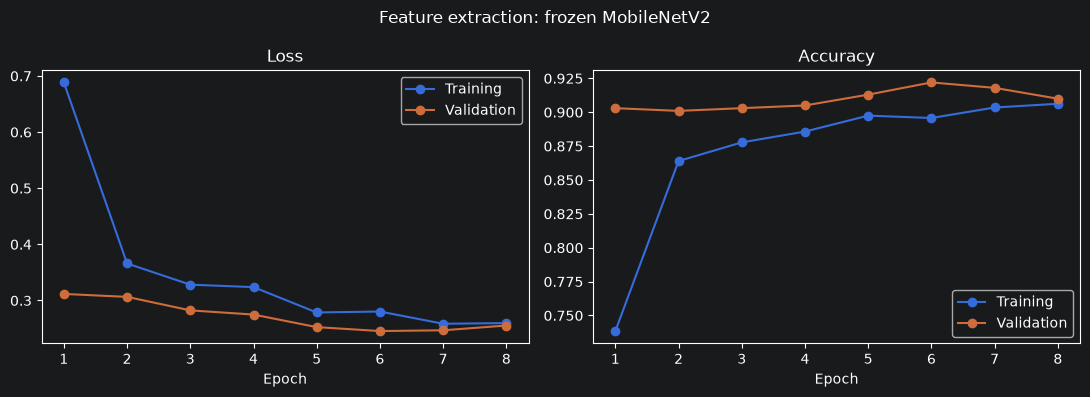

In [14]:
def plot_history(history, title):
    history_dict = history.history
    epochs = range(1, len(history_dict["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].plot(epochs, history_dict["loss"], marker="o", label="Training")
    axes[0].plot(epochs, history_dict["val_loss"], marker="o", label="Validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(epochs, history_dict["accuracy"], marker="o", label="Training")
    axes[1].plot(epochs, history_dict["val_accuracy"], marker="o", label="Validation")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_history(history_feature, "Feature extraction: frozen MobileNetV2")

## 12. Validate the frozen-backbone model

We use validation data to compare training stages and make model-development decisions. We do not use the final test set for this comparison.

In [15]:
def predict_dataset(model_to_evaluate, dataset):
    y_true = np.concatenate([labels.numpy() for _, labels in dataset], axis=0)
    y_prob = model_to_evaluate.predict(dataset, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)
    return y_true, y_pred, y_prob


def summarize_predictions(y_true, y_pred, label):
    summary = {
        "stage": label,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
    }
    return summary


val_true, val_pred_feature, val_prob_feature = predict_dataset(model, val_ds)
feature_summary = summarize_predictions(val_true, val_pred_feature, "Frozen backbone")
feature_summary

{'stage': 'Frozen backbone',
 'accuracy': 0.922,
 'macro_f1': 0.9219178393992741,
 'weighted_f1': 0.9219178393992741}

## 13. Optional offline feature caching

Another feature-extraction workflow computes the frozen backbone embeddings once, stores them, and trains a lightweight classifier on those fixed vectors. This can be efficient when augmentation is not required and the backbone remains frozen.

The `embedding_model` below returns the pooled representation immediately before the new classification head. We use an unshuffled dataset so the feature rows remain aligned with `y_train` and `y_val`.

In [16]:
embedding_model = keras.Model(
    inputs=model.input,
    outputs=model.get_layer("global_average_pooling").output,
    name="mobilenetv2_embedding_model",
)

train_embeddings = embedding_model.predict(train_eval_ds, verbose=0)
val_embeddings = embedding_model.predict(val_ds, verbose=0)

print("Train embeddings:", train_embeddings.shape)
print("Validation embeddings:", val_embeddings.shape)

Train embeddings: (4000, 1280)
Validation embeddings: (1000, 1280)


In [17]:
linear_probe = LogisticRegression(max_iter=1000, random_state=SEED)
linear_probe.fit(train_embeddings, y_train)
val_pred_linear = linear_probe.predict(val_embeddings)
linear_probe_summary = summarize_predictions(y_val, val_pred_linear, "Cached features + Logistic Regression")
linear_probe_summary

{'stage': 'Cached features + Logistic Regression',
 'accuracy': 0.919,
 'macro_f1': 0.9190599529717729,
 'weighted_f1': 0.9190599529717728}

This offline approach is fast after feature extraction, but it does not update the backbone and does not expose the classifier to new random image augmentations on each epoch. End-to-end feature extraction with a frozen backbone is more flexible; selective fine-tuning is the next step.

## 14. Fine-tune selected upper layers

We now unfreeze only a small group of upper MobileNetV2 layers. A lower learning rate is essential because the backbone already contains useful pretrained parameters.

**Batch Normalization precaution:** keep Batch Normalization layers non-trainable and call the backbone with `training=False`. This avoids updating moving mean and variance statistics using a small target dataset. Also, after changing any `trainable` flags, compile the model again so the optimizer uses the updated trainable-variable set.

In [18]:
base_model.trainable = True

# Fine-tune only the last 30 layers as a conservative starting point.
FINE_TUNE_LAST_N_LAYERS = 30
fine_tune_at = max(0, len(base_model.layers) - FINE_TUNE_LAST_N_LAYERS)

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

for layer in base_model.layers[fine_tune_at:]:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

print("Total backbone layers:", len(base_model.layers))
print("Fine-tuning begins at layer:", fine_tune_at)
print("Trainable backbone layers:", sum(layer.trainable for layer in base_model.layers))
print("Trainable BatchNormalization layers:", sum(
    layer.trainable for layer in base_model.layers
    if isinstance(layer, keras.layers.BatchNormalization)
))

Total backbone layers: 154
Fine-tuning begins at layer: 124
Trainable backbone layers: 19
Trainable BatchNormalization layers: 0


The call `base_model(x, training=False)` was used when building the model. It keeps the backbone's Batch Normalization layers in inference mode even after selected layers are unfrozen. This is a separate but complementary safeguard to setting each Batch Normalization layer's `trainable` attribute to `False`.

In [19]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)

fine_tune_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
    ),
    keras.callbacks.ModelCheckpoint(
        "best_fine_tuned_model.keras",
        monitor="val_loss",
        save_best_only=True,
    ),
]

EPOCHS_FINE_TUNE = 4
history_fine_tune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE_TUNE,
    callbacks=fine_tune_callbacks,
)

Epoch 1/4


G:\CancerAI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


125/125 ━━━━━━━━━━━━━━━━━━━━ 27s 178ms/step - accuracy: 0.9112 - loss: 0.2501 - val_accuracy: 0.9280 - val_loss: 0.2362
Epoch 2/4
125/125 ━━━━━━━━━━━━━━━━━━━━ 24s 192ms/step - accuracy: 0.9147 - loss: 0.2228 - val_accuracy: 0.9220 - val_loss: 0.2406
Epoch 3/4
125/125 ━━━━━━━━━━━━━━━━━━━━ 21s 168ms/step - accuracy: 0.9285 - loss: 0.1987 - val_accuracy: 0.9250 - val_loss: 0.2302
Epoch 4/4
125/125 ━━━━━━━━━━━━━━━━━━━━ 24s 192ms/step - accuracy: 0.9293 - loss: 0.1894 - val_accuracy: 0.9300 - val_loss: 0.2185


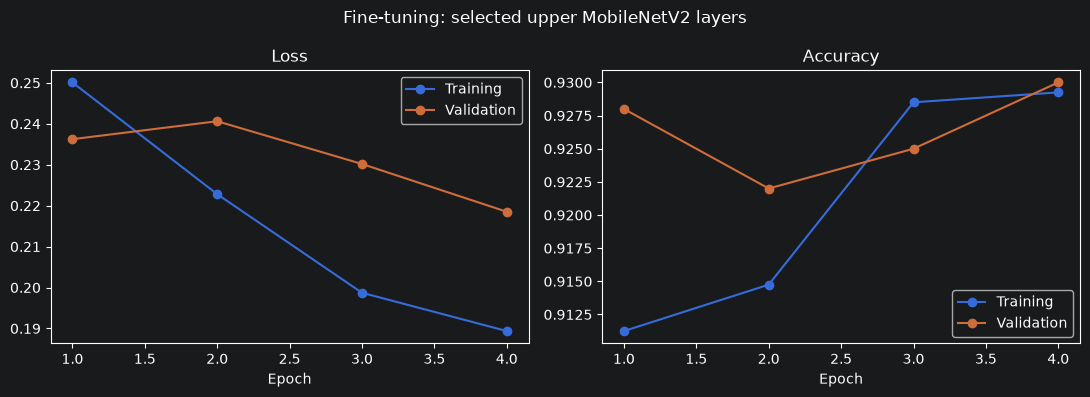

In [20]:
plot_history(history_fine_tune, "Fine-tuning: selected upper MobileNetV2 layers")

## 15. Compare validation performance across stages

Compare the validation metrics from the frozen-backbone classifier, cached-feature linear probe, and fine-tuned model. A fine-tuned model is not automatically better: keep it only if it improves validation performance without showing unstable learning or a widening training/validation gap.

In [21]:
val_true_final, val_pred_fine, val_prob_fine = predict_dataset(model, val_ds)
fine_summary = summarize_predictions(val_true_final, val_pred_fine, "Fine-tuned MobileNetV2")

comparison_rows = [feature_summary, linear_probe_summary, fine_summary]
for row in comparison_rows:
    print(
        f"{row['stage']:<38} "
        f"accuracy={row['accuracy']:.4f}  "
        f"macro-F1={row['macro_f1']:.4f}  "
        f"weighted-F1={row['weighted_f1']:.4f}"
    )

Frozen backbone                        accuracy=0.9220  macro-F1=0.9219  weighted-F1=0.9219
Cached features + Logistic Regression  accuracy=0.9190  macro-F1=0.9191  weighted-F1=0.9191
Fine-tuned MobileNetV2                 accuracy=0.9300  macro-F1=0.9301  weighted-F1=0.9301


The validation set is used for model selection. The final test set remains untouched until the model-development decisions are complete. For a real biomedical study, model selection should also be followed by evaluation on an independent external cohort whenever possible.

## 16. Final evaluation on the held-out test set

After choosing the model-development strategy, evaluate the final model once on the held-out test subset. Report overall and per-class metrics; accuracy alone can hide class-specific failures.

In [22]:
y_test_true, y_test_pred, y_test_prob = predict_dataset(model, test_ds)

print("Test accuracy:", accuracy_score(y_test_true, y_test_pred))
print("Test macro-F1:", f1_score(y_test_true, y_test_pred, average="macro"))
print("Test weighted-F1:", f1_score(y_test_true, y_test_pred, average="weighted"))

print("\nClassification report:")
print(
    classification_report(
        y_test_true,
        y_test_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        zero_division=0,
    )
)

Test accuracy: 0.9316666666666666
Test macro-F1: 0.9316587903472915
Test weighted-F1: 0.9316587903472915

Classification report:
              precision    recall  f1-score   support

    airplane       0.94      0.92      0.93       300
  automobile       0.94      0.93      0.94       300
        ship       0.92      0.94      0.93       300
       truck       0.93      0.93      0.93       300

    accuracy                           0.93      1200
   macro avg       0.93      0.93      0.93      1200
weighted avg       0.93      0.93      0.93      1200



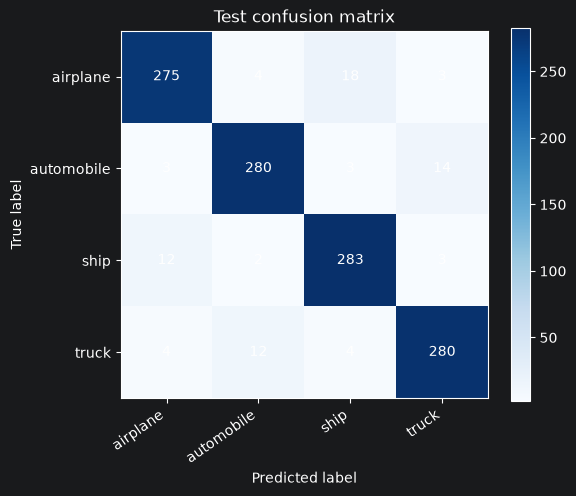

In [23]:
cm = confusion_matrix(y_test_true, y_test_pred, labels=np.arange(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(cm, cmap="Blues")
ax.set_title("Test confusion matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=35, ha="right")
ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
for row in range(NUM_CLASSES):
    for col in range(NUM_CLASSES):
        ax.text(col, row, str(cm[row, col]), ha="center", va="center")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

## 17. Inspect confident errors

A useful error-analysis step is to inspect images the model predicts confidently but incorrectly. Such errors may reveal visually ambiguous classes, dataset artifacts, or limits in the pretrained representation.

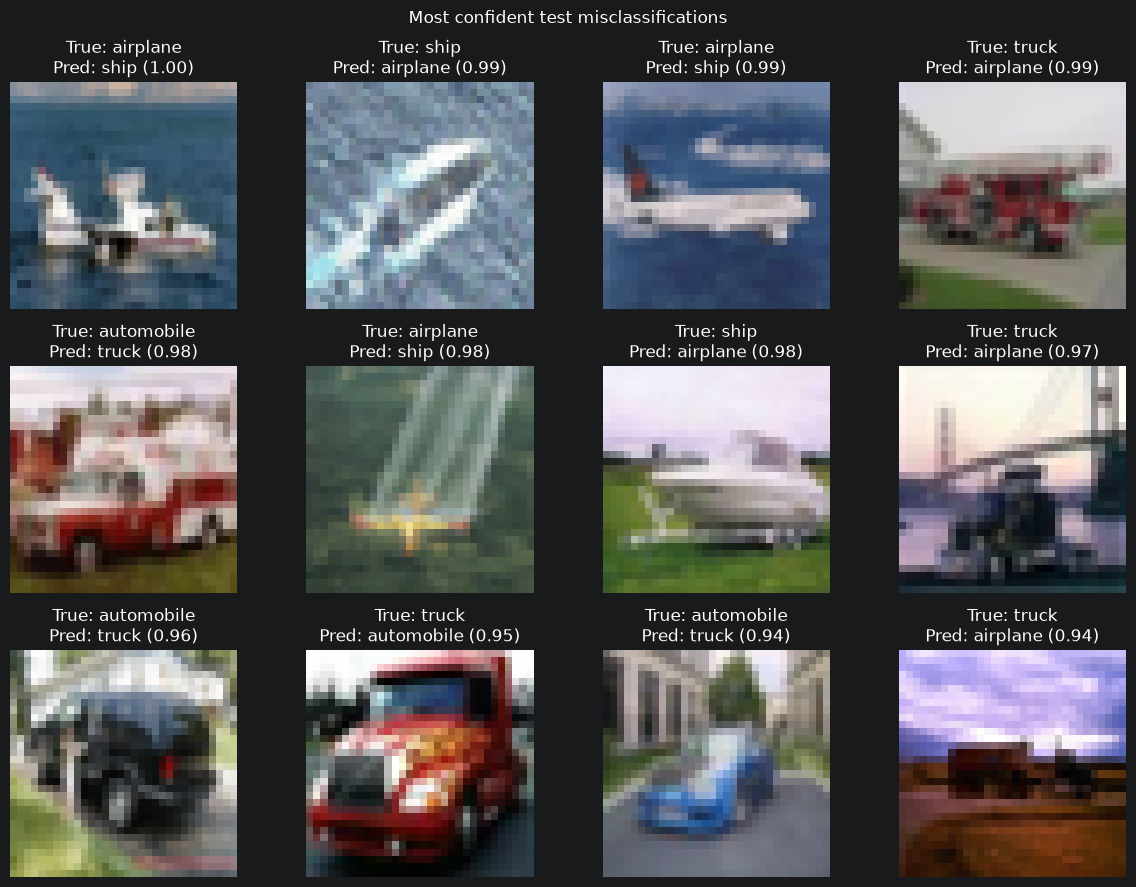

In [24]:
wrong_indices = np.flatnonzero(y_test_pred != y_test_true)
if len(wrong_indices) == 0:
    print("No test errors were found in this run.")
else:
    confidence = np.max(y_test_prob, axis=1)
    ranked_errors = wrong_indices[np.argsort(confidence[wrong_indices])[::-1]]
    selected_errors = ranked_errors[:12]

    fig, axes = plt.subplots(3, 4, figsize=(12, 9))
    for ax, idx in zip(axes.flat, selected_errors):
        ax.imshow(x_test[idx])
        ax.set_title(
            f"True: {CLASS_NAMES[int(y_test_true[idx])] }\n"
            f"Pred: {CLASS_NAMES[int(y_test_pred[idx])] } "
            f"({confidence[idx]:.2f})"
        )
        ax.axis("off")
    for ax in axes.flat[len(selected_errors):]:
        ax.axis("off")
    plt.suptitle("Most confident test misclassifications")
    plt.tight_layout()
    plt.show()

## 18. Compare MobileNetV2, ResNet50, and EfficientNetB0

These backbones represent different design priorities. The best choice depends on dataset size, target image resolution, available compute, latency constraints, and domain similarity.

| Architecture | General design idea | Preprocessing requirement | Practical note |
|---|---|---|---|
| MobileNetV2 | Inverted residual blocks and depthwise separable convolutions | Scale to `[-1, 1]` | Lightweight starting point |
| ResNet50 | Residual skip connections | RGB → BGR and ImageNet channel centering | Larger conventional backbone |
| EfficientNetB0 | Compound scaling of depth, width, and resolution | Built-in rescaling; input in `[0, 255]` | Efficient accuracy/compute trade-off |

Do not compare architectures using only parameter count. Also measure validation performance, inference latency, memory use, and stability on the target domain. Always use the preprocessing function that matches the selected application.

In [25]:
# Optional: inspect backbone output shapes and parameter counts without downloading pretrained weights.
# These are architecture-only instances, not trained models.
application_constructors = {
    "MobileNetV2": keras.applications.MobileNetV2,
    "ResNet50": keras.applications.ResNet50,
    "EfficientNetB0": keras.applications.EfficientNetB0,
}

architecture_summary = []
for name, constructor in application_constructors.items():
    candidate = constructor(
        include_top=False,
        weights=None,
        input_shape=IMG_SIZE + (3,),
        pooling=None,
    )
    architecture_summary.append(
        {
            "model": name,
            "output_shape": str(candidate.output_shape),
            "parameters": candidate.count_params(),
        }
    )
    del candidate
    gc.collect()

for row in architecture_summary:
    print(row)

{'model': 'MobileNetV2', 'output_shape': '(None, 3, 3, 1280)', 'parameters': 2257984}
{'model': 'ResNet50', 'output_shape': '(None, 3, 3, 2048)', 'parameters': 23587712}
{'model': 'EfficientNetB0', 'output_shape': '(None, 3, 3, 1280)', 'parameters': 4049571}


### Correct preprocessing examples

Use one of the following preprocessing routes for the corresponding backbone. The main notebook model uses an internal MobileNetV2-compatible `Rescaling` layer, so these external preprocessing calls are demonstrations and should not be applied again to data passed through that model.

In [26]:
# Demonstrate architecture-specific preprocessing on the same raw sample.
raw_sample = tf.cast(x_train[:1], tf.float32)

processed_by_architecture = {
    "MobileNetV2": keras.applications.mobilenet_v2.preprocess_input(raw_sample),
    "ResNet50": keras.applications.resnet.preprocess_input(raw_sample),
    "EfficientNetB0": keras.applications.efficientnet.preprocess_input(raw_sample),
}

for name, tensor in processed_by_architecture.items():
    print(
        name,
        "shape=", tuple(tensor.shape),
        "range=", (float(tf.reduce_min(tensor)), float(tf.reduce_max(tensor)))
    )

MobileNetV2 shape= (1, 32, 32, 3) range= (-1.0, 1.0)
ResNet50 shape= (1, 32, 32, 3) range= (-120.68000030517578, 151.06100463867188)
EfficientNetB0 shape= (1, 32, 32, 3) range= (0.0, 255.0)


## 19. Save and reload the final model

The model includes the image augmentation and MobileNetV2 rescaling layers, so it expects RGB pixel values in the original `[0, 255]` range at inference time. The backbone weights and new classifier are saved together.

In [27]:
MODEL_PATH = "transfer_learning_mobilenetv2_cifar10.keras"
model.save(MODEL_PATH)
print("Saved:", MODEL_PATH)

reloaded_model = keras.models.load_model(MODEL_PATH)
reload_probabilities = reloaded_model.predict(test_ds.take(1), verbose=0)
print("Reloaded model output shape:", reload_probabilities.shape)

Saved: transfer_learning_mobilenetv2_cifar10.keras
Reloaded model output shape: (32, 4)


## 20. Limitations and responsible use

1. **Source–target domain gap:** ImageNet consists primarily of natural images. Histology, radiology, microscopy, and other biomedical images can differ substantially in texture, color, scale, acquisition physics, and label definitions.
2. **Resolution:** resizing a low-resolution source image does not create new visual information. In medical imaging, choose image resolution and field of view based on the clinical task.
3. **Patient-level leakage:** multiple slices, patches, or images from one patient must not be split across training and test sets when the intended claim is patient-level generalization.
4. **External validation:** evaluate on data from a different institution, scanner, time period, or population when possible.
5. **Class imbalance:** report per-class sensitivity/recall, precision, F1, and confusion matrices; do not rely on accuracy alone.
6. **Calibration:** high softmax confidence is not proof that a prediction is correct or clinically reliable.
7. **Pretraining provenance:** document the source dataset, license, preprocessing, and pretrained checkpoint used.
8. **Clinical interpretation:** this notebook is educational and does not create a clinically validated diagnostic model.

## 21. Key takeaways

- Transfer learning starts from pretrained visual representations instead of random initialization.
- Feature extraction freezes the backbone and trains a new classifier head.
- Fine-tuning should begin only after the new head has learned a reasonable solution.
- Use a much smaller learning rate during fine-tuning and recompile after changing trainable layers.
- Keep Batch Normalization in inference mode as a safe default when fine-tuning a small target dataset.
- `include_top=False` removes the original classifier; Global Average Pooling converts spatial feature maps into compact vectors.
- Preprocessing is architecture-specific. Never apply it twice.
- Validation data support model selection; the test set is reserved for final evaluation.
- In biomedical applications, patient-level splitting and external validation are essential safeguards.

## 22. Exercises

1. Change `MAX_TRAIN_PER_CLASS` from 1,000 to 250. Compare feature extraction and fine-tuning. Does the smaller dataset change the validation gap?
2. Compare `IMG_SIZE = (96, 96)` with `(128, 128)`. Record runtime, parameter count, and validation macro-F1.
3. Change the number of fine-tuned layers from 30 to 10 and 50. Compare validation metrics and training stability.
4. Try `ResNet50` or `EfficientNetB0` as the backbone. Make sure you use its own preprocessing convention.
5. Compare `GlobalAveragePooling2D` with `Flatten`. Record the number of parameters in the new classifier head.
6. Disable data augmentation. Does training accuracy improve faster? What happens to validation performance?
7. Create a plot comparing trainable parameter counts during feature extraction and fine-tuning.
8. Write a short report describing how ImageNet-to-medical-image domain shift could affect the model.

### Challenge

Design a patient-level transfer-learning experiment for a small medical imaging dataset. Specify the split strategy, the pretrained backbone, preprocessing, fine-tuning plan, metrics, external validation strategy, and limitations. Do not claim clinical validity from an internal test result alone.

## 23. References and further reading

1. Keras. **Transfer learning & fine-tuning.** https://keras.io/guides/transfer_learning/
2. TensorFlow. **Transfer learning and fine-tuning.** https://www.tensorflow.org/tutorials/images/transfer_learning
3. Keras Applications. **MobileNet and MobileNetV2.** https://keras.io/api/applications/mobilenet/
4. Keras Applications. **ResNet and ResNetV2.** https://keras.io/api/applications/resnet/
5. Keras Applications. **EfficientNet B0–B7.** https://keras.io/api/applications/efficientnet/
6. Krizhevsky, A. (2009). **Learning Multiple Layers of Features from Tiny Images.** CIFAR-10 dataset page: https://www.cs.toronto.edu/~kriz/cifar.html
7. TensorFlow. **Install TensorFlow with pip.** https://www.tensorflow.org/install/pip

---

**End of Notebook 09 — Transfer Learning and Pretrained Models**